In [1]:
import sys; sys.path.append("..")

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report

model = joblib.load("../model/sentiment.joblib")
train = pd.read_csv("../data/imdb/train.csv")
test = pd.read_csv("../data/imdb/test.csv")

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [2]:
baseline = DummyClassifier(strategy="most_frequent").fit(train["review"], train["label"])

y_base = baseline.predict(test["review"])
y_pred = model.predict(test["review"])

print("F1 macro baseline :", round(f1_score(test["label"], y_base, average="macro"), 3))
print("F1 macro modèle   :", round(f1_score(test["label"], y_pred, average="macro"), 3))
print(classification_report(test["label"], y_pred, target_names=["négatif", "positif"]))

F1 macro baseline : 0.333
F1 macro modèle   : 0.799
              precision    recall  f1-score   support

     négatif       0.83      0.75      0.79       100
     positif       0.77      0.85      0.81       100

    accuracy                           0.80       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.80      0.80       200



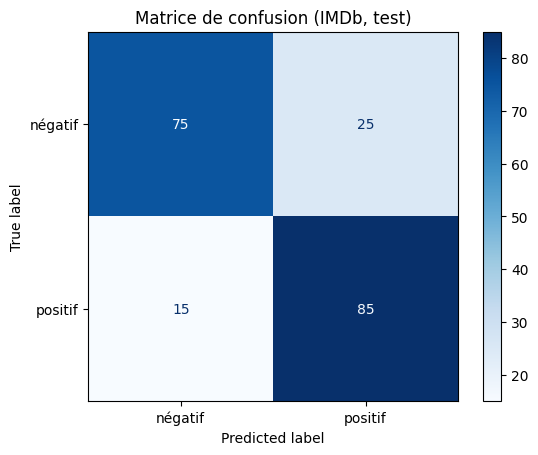

In [3]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    test["label"], y_pred,
    display_labels=["négatif", "positif"],
    cmap="Blues",
)
plt.title("Matrice de confusion (IMDb, test)")
plt.show()

In [4]:
pd.set_option("display.max_colwidth", None)

erreurs = test.copy()
erreurs["pred"] = y_pred
erreurs["proba_pos"] = model.predict_proba(test["review"])[:, 1].round(2)
erreurs["nb_mots"] = erreurs["review"].str.split().str.len()

erreurs = erreurs[erreurs["label"] != erreurs["pred"]]
erreurs.sort_values("proba_pos", ascending=False)

,review,label,pred,proba_pos,nb_mots
168,"All in all, a great disappointment.",0,1,0.63,6
155,"At any rate this film stinks, its not funny, and Fulci should have stayed with giallo and supernatural zombie movies.",0,1,0.63,20
79,the movie is littered with overt racial slurs towards the black cast members and in return the whites are depicted as morons and boobs.,0,1,0.63,24
1,but the movie makes a lot of serious mistakes.,0,1,0.58,9
108,The characters were very 'stagey' and the storyline was a lot like a stage farce.,0,1,0.58,15
101,And the accents are absolutely abysmal!,0,1,0.58,6
122,"In fact, this stinker smells like a direct-to-video release.",0,1,0.57,9
138,Your brain will attempt to shut-down as part of a primal impulse of self-preservation.,0,1,0.57,14
169,All in all its an insult to one's intelligence and a huge waste of money.,0,1,0.57,15
70,If it was to turn my good day feeling into a night of disturbing memories than I guess he succeeded.,0,1,0.57,20


## Analyse d'erreurs (IMDb, test)

**Résultats** : F1 macro de **0,799** contre **0,333** pour la baseline majoritaire. Sur 200 avis : 160 bien classés, **25 faux positifs** (négatifs classés positifs) et **15 faux négatifs** (positifs classés négatifs).

**Le modèle hésite quand il se trompe.** Presque toutes les erreurs ont une proba entre 0,40 et 0,63, donc proche du seuil de 0,5. Une seule erreur est franche : « Predictable, but not a bad watch. » (proba positive = 0,15).

| Type d'erreur | Exemples | Explication |
|---|---|---|
| **Négation** | « It is not good. » (classé positif) · « its not funny » · « I don't think you will be disappointed. » (classé négatif) · « Predictable, but not a bad watch. » (classé négatif) | TF-IDF sur unigrammes traite « not » et « good » séparément. La négation n'inverse pas le sens du mot qui la suit. |
| **Mot positif dans un avis négatif** (et inversement) | « a great disappointment » · « my good day feeling » · « better than 95% of the **garbage** in the theatres » · « finds her room **blown up** » | Le modèle additionne le poids des mots sans comprendre la phrase dans sa globalité. |
| **Ironie / sarcasme** | « Your brain will attempt to shut-down as part of a primal impulse of self-preservation. » · « This film (and I use that word loosely)… » · « a must see for anyone with no social or physical outlets » | Le sentiment passe par l'ironie, sans mot explicitement négatif ou positif. |
| **Vocabulaire rare** | stinks, stinker, abysmal, stagey, yawn · thrilled, fascinated, top notch, utterly convincing, rocked | Avec 797 phrases d'entraînement (2 622 mots de vocabulaire), ces mots apparaissent trop peu pour avoir un poids fiable. |
| **Avis très courts** | « Hated it. » (proba = 0,50) · « Anne Heche was utterly convincing. » | Avec 2 à 5 mots, un seul mot inconnu suffit à faire basculer la prédiction. |
| **Phrases descriptives / label discutable** | « The story unfolds in 18th century Jutland… » · « the lack of notable gore » · « amazing performances of Leni Parker… » (labellisé négatif) | Les phrases sont extraites d'avis plus longs : prises seules, elles sont neutres ou ambiguës. |

**Pourquoi le modèle rate plus de négatifs ?** Les avis négatifs utilisent souvent des négations de mots positifs (« not good », « not funny ») et de l'ironie, deux cas que TF-IDF + régression logistique gère mal.

**Pistes d'amélioration**
- Plus de données (par exemple les 3 000 phrases UCI : IMDb + Amazon + Yelp) pour enrichir le vocabulaire.
- Un prétraitement des négations (fusionner « not good » en `not_good`), utile quand les données sont trop peu nombreuses pour que les bigrammes soient efficaces.
- Un modèle qui comprend le contexte (embeddings ou modèle de type BERT), hors du périmètre du hackathon.